# 07 · Recency experiments: do recent matches deserve more weight?

**Question:** football changes over time: tactics, the number of goals, how strong home advantage
is. Would Logistic Regression predict better if it paid more attention to recent seasons than to
the 1990s?

**Method:** the walk-forward backtest from commit 10, for seasons 2018-19 to 2024-25, run once per
training strategy. Everything else is identical:
- the same Logistic Regression grid and feature sets;
- past-only tuning (fit on seasons up to S-2, score on S-1);
- refit on seasons up to S-1;
- scoring on the same fixtures.

## The three approaches

| Approach | Training rows | Weights | Settings tested |
|---|---|---|---|
| **Expanding (control)** | Every earlier season, from 1993-94 | All equal | — |
| **Rolling window** | Only the last *k* training seasons | All equal | *k* = 3, 5, 10 |
| **Exponential decay** | Every earlier season | Older matches count less | half-life *h* = 1, 2, 5 years |

**Weight formula (exponential decay).** Let `cutoff` be the date of the most recent training match.
For every training match *i*:

```
age_i = (cutoff - date_i) in days / 365.25        (years)
raw_i = 0.5 ** (age_i / h)                         (= exp(-ln 2 * age_i / h))
w_i   = raw_i / mean(raw)                          (normalised: mean weight = 1)
```

- **Halving:** a match played *h* years before the cutoff counts half as much as the latest one,
  and one played 2*h* years before counts a quarter.
- **Normalisation:** a mean weight of 1 keeps the total weight equal to the number of matches, as
  in the control, so the regularisation setting `C` means the same thing for every strategy.
- **Where weights apply:** they go to the Logistic Regression step only. The imputer and scaler
  are fitted on the same rows without weights.
- **Effective sample size** `(Σw)² / Σw²` measures how many equally weighted matches the weighted
  training set is worth.

**The same strategy in both steps.** Within each fold, the strategy is applied to the inner
tuning fits (train up to S-2, so the cutoff is the end of S-2, or the window ends at S-2) and to
the final fit (train up to S-1). Each strategy's feature set and `C` are therefore chosen *for
that strategy*, from earlier seasons only.

**What a window changes, and what it doesn't.** A window only changes which matches are
*training examples*. Every match's features still describe its own pre-match history, which is
always leakage-safe.

**Untouched:**
- 2025-26 and 2026-27 play no part in choosing a strategy.
- The commit-7 models, notebooks 01–06 and the commit-10 backtest files are unchanged. Results
  here go to `outputs/recency/`.

**Multiple comparisons.** Six strategies are compared with one control, so by chance alone one of
them could look better on a single season. The analysis therefore looks for consistency across
seasons, not just a pooled number.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

from src.backtest import (
    BACKTEST_SEASONS, BASELINE, METRICS, common_fixtures, pooled_bootstrap, pooled_metrics, save_backtest,
    season_metrics, seasonal_bootstrap,
)
from src.bookmaker import BOOKMAKER_LABEL
from src.config import FIGURES_DIR
from src.feature_engineering import load_features
from src.preprocessing import load_matches
from src.recency import (
    CONTROL, RECENCY_DIR, STRATEGIES, exponential_weights, run_recency_backtest, season_differences,
    season_level_summary, strategy_table,
)
from src.train import season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
matches = load_matches()

start = time.time()
experiment = run_recency_backtest(features, matches)  # 7 strategies x 7 seasons, Logistic Regression
paths = save_backtest(experiment, RECENCY_DIR)
print(f"Experiment finished in {(time.time() - start) / 60:.1f} minutes")
for name, path in paths.items():
    print(f"saved {name}: {path.relative_to(path.parents[2])}")

predictions = experiment.predictions
LABELS = [s.label for s in STRATEGIES]
OTHERS = [label for label in LABELS if label != CONTROL.label]
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}

Experiment finished in 2.1 minutes
saved predictions: outputs\recency\predictions.csv
saved folds: outputs\recency\folds.csv


In [2]:
# --- Chart style (same as notebooks 01-06) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE = "#e1e0d9", "#c3c2b7"
# Control in ink; windows as a blue ramp, half-lives as an orange ramp (darker = longer memory)
COLORS = {CONTROL.label: INK,
          "Window: 3 seasons": "#86b6ef", "Window: 5 seasons": "#2a78d6", "Window: 10 seasons": "#104281",
          "Half-life: 1 year": "#f3a27f", "Half-life: 2 years": "#eb6834", "Half-life: 5 years": "#a3401b",
          BOOKMAKER_LABEL: "#eda100", BASELINE: "#a3a29b"}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 1. What each strategy does to the training data

The example below is the final fit of the 2024-25 fold: every completed match from 1993-94 to
2023-24.

In [3]:
last_fold_train = features[(features["season_start"] <= BACKTEST_SEASONS[-1] - 1) & features["result"].notna()]
table = strategy_table(STRATEGIES, last_fold_train)
table.style.format({"rows_used": "{:,}", "effective_matches": "{:,.0f}", "weight_of_last_season": "{:.1%}"})

,kind,setting,rows_used,first_season,last_season,effective_matches,weight_of_last_season
strategy,,,,,,,
Expanding (control),expanding,"all seasons, equal weights","10,966",1993,2023,"10,966",3.5%
Window: 3 seasons,rolling window,3 seasons,"1,140",2021,2023,"1,140",33.3%
Window: 5 seasons,rolling window,5 seasons,"1,900",2019,2023,"1,900",20.0%
Window: 10 seasons,rolling window,10 seasons,"3,800",2014,2023,"3,800",10.0%
Half-life: 1 year,exponential decay,half-life 1 year,"10,966",1993,2023,"1,120",49.7%
Half-life: 2 years,exponential decay,half-life 2 years,"10,966",1993,2023,"2,208",29.2%
Half-life: 5 years,exponential decay,half-life 5 years,"10,966",1993,2023,"5,240",13.2%


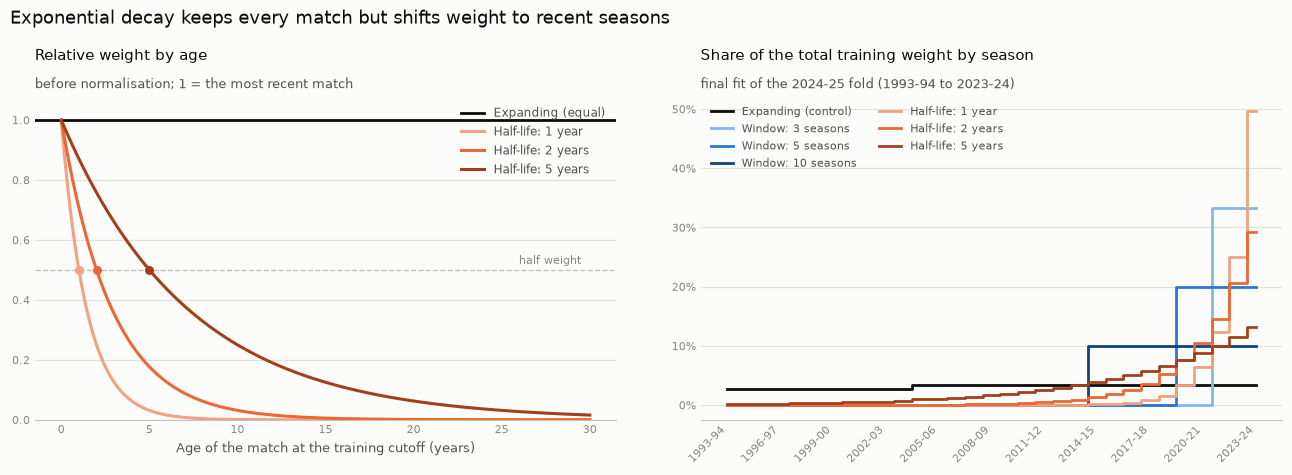

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURFACE)

ax = axes[0]
age = np.linspace(0, 30, 301)
ax.axhline(1, color=INK, linewidth=2, label="Expanding (equal)")
for h in (1, 2, 5):
    label = f"Half-life: {h} year" + ("s" if h > 1 else "")
    ax.plot(age, 0.5 ** (age / h), color=COLORS[label], linewidth=2.2, label=label)
    ax.scatter([h], [0.5], s=30, color=COLORS[label], zorder=3)
ax.axhline(0.5, color=BASELINE_LINE, linewidth=1, linestyle="--")
ax.text(29.5, 0.52, "half weight", ha="right", fontsize=8, color=MUTED)
ax.set_xlabel("Age of the match at the training cutoff (years)", fontsize=9, color=INK_2)
ax.set_ylim(0, 1.08)
style_axes(ax)
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper right")
set_title(ax, "Relative weight by age", "before normalisation; 1 = the most recent match", size=11)

ax = axes[1]
seasons = sorted(last_fold_train["season_start"].unique())
x = np.arange(len(seasons))
for strategy in STRATEGIES:
    rows, weights = strategy.prepare(last_fold_train)
    w = np.ones(len(rows)) if weights is None else weights
    share = pd.Series(w, index=rows.index).groupby(rows["season_start"]).sum().reindex(seasons, fill_value=0)
    share = share / share.sum()
    ax.plot(x, share, color=COLORS[strategy.label], linewidth=2, drawstyle="steps-mid", label=strategy.label)
ax.set_xticks(x[::3], [season_name(s) for s in seasons[::3]], fontsize=8, rotation=45, ha="right")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
style_axes(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_2, loc="upper left", ncols=2)
set_title(ax, "Share of the total training weight by season", "final fit of the 2024-25 fold (1993-94 to 2023-24)",
          size=11)
fig.suptitle("Exponential decay keeps every match but shifts weight to recent seasons",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "34_recency_weights.png")
plt.show()

**Interpretation**

- **The windows throw data away.** For the 2024-25 fold, a 3-season window trains on 1,140
  matches instead of 10,966; a 10-season window keeps 3,800.
- **Exponential decay keeps every match but concentrates the weight:**

  | Half-life | Weight on the latest season | Effective matches |
  |---|---|---|
  | 1 year | about half | about 1,120 |
  | 2 years | 29% | about 2,200 |
  | 5 years | 13% | about 5,200 |

- **In the control**, every one of the 31 training seasons counts equally, so the latest season
  carries only 3.5% of the weight.
- **Comparable amounts of data:** a 1-year half-life is worth about as much data as a 3-season
  window, and a 2-year half-life about as much as a 5-season window. The difference is that decay
  fades out smoothly instead of cutting off.

## 2. Settings chosen by each strategy

Each fold chose `C` and the feature set for each strategy, using only earlier seasons.

In [5]:
folds = experiment.folds.copy()
folds["selected"] = folds["feature_set"] + ", C = " + folds["params"].str.extract(r'"C": ([0-9.e-]+)')[0]
settings = folds.pivot(index="season", columns="strategy_label", values="selected")[LABELS]
settings.index = settings.index.map(SEASON_LABELS)
settings

strategy_label,Expanding (control),Window: 3 seasons,Window: 5 seasons,Window: 10 seasons,Half-life: 1 year,Half-life: 2 years,Half-life: 5 years
season,,,,,,,
2018-19,"all, C = 0.01","all, C = 0.01","all, C = 0.03","all, C = 0.01","all, C = 0.001","all, C = 0.003","all, C = 0.003"
2019-20,"all, C = 0.0003","all, C = 0.003","all, C = 0.003","all, C = 0.001","all, C = 0.0003","all, C = 0.0003","all, C = 0.0003"
2020-21,"compact, C = 0.1","compact, C = 0.003","compact, C = 0.03","compact, C = 0.03","compact, C = 0.0003","compact, C = 0.0003","compact, C = 0.03"
2021-22,"all, C = 1.0","compact, C = 0.003","compact, C = 0.003","compact, C = 0.01","compact, C = 0.001","compact, C = 0.001","all, C = 0.003"
2022-23,"compact, C = 0.0003","all, C = 0.003","all, C = 0.003","compact, C = 0.001","all, C = 0.0001","all, C = 0.0003","compact, C = 0.0003"
2023-24,"compact, C = 1.0","compact, C = 0.003","all, C = 0.003","all, C = 0.001","compact, C = 0.0003","all, C = 0.0003","all, C = 0.0003"
2024-25,"all, C = 0.001","compact, C = 0.003","compact, C = 0.003","compact, C = 0.001","compact, C = 0.0003","compact, C = 0.0003","all, C = 0.0003"


**Interpretation**

- **Feature sets:** in 2018-19 to 2020-21 every strategy picks the same feature set; later
  seasons differ.
- **Regularisation:** the recency strategies mostly pick strong regularisation.
  - Half-life strategies usually choose `C = 0.0003` (range 0.0001–0.03).
  - Windows choose 0.001–0.03.
  - The control sometimes chooses 0.1 or 1.0.
  - Fewer or down-weighted training matches make the inner validation favour smaller
    coefficients. This is the shared model-selection procedure working as intended: each strategy
    gets the regularisation that suits it.
- **The control's own choices jump around**, including `C = 1.0` in 2021-22 and 2023-24. As in
  commit 10, the tuning landscape is flat.

## 3. Season by season

Every strategy is scored on the same 2,657 fixtures (those with complete bookmaker odds; 3 of
2,660 have none).

In [6]:
fixtures_per_strategy = common_fixtures(predictions).groupby("forecast").size()
assert fixtures_per_strategy[LABELS].nunique() == 1
print(f"Fixtures per strategy: {fixtures_per_strategy[LABELS].iloc[0]:,} (identical sets checked)")

seasonal = season_metrics(predictions)
log_loss = seasonal["log_loss"].unstack("forecast")[LABELS + [BOOKMAKER_LABEL]]
log_loss.index = log_loss.index.map(SEASON_LABELS)
(log_loss.style.format("{:.4f}").highlight_min(axis=1, subset=LABELS, color="#d9f2e6")
 .set_caption("Log loss by season (lowest strategy highlighted)"))

Fixtures per strategy: 2,657 (identical sets checked)


forecast,Expanding (control),Window: 3 seasons,Window: 5 seasons,Window: 10 seasons,Half-life: 1 year,Half-life: 2 years,Half-life: 5 years,Bookmaker (Bet365)
season,,,,,,,,
2018-19,0.9848,0.9843,0.9843,0.9791,0.9935,0.9842,0.9803,0.9448
2019-20,0.9920,0.9901,0.9967,0.9933,0.9954,0.9925,0.9909,0.9626
2020-21,0.9488,0.9540,0.9520,0.9463,0.9492,0.9491,0.9456,0.9339
2021-22,1.0047,0.9849,0.9856,0.9954,0.9950,0.9894,0.9947,0.9758
2022-23,0.9814,0.9862,0.9802,0.9771,0.9846,0.9790,0.9783,0.9828
2023-24,0.9885,0.9982,1.0026,0.9934,0.9967,0.9971,0.9883,0.9668
2024-25,0.9836,0.9975,0.9922,0.9907,0.9919,0.9907,0.9866,0.9548


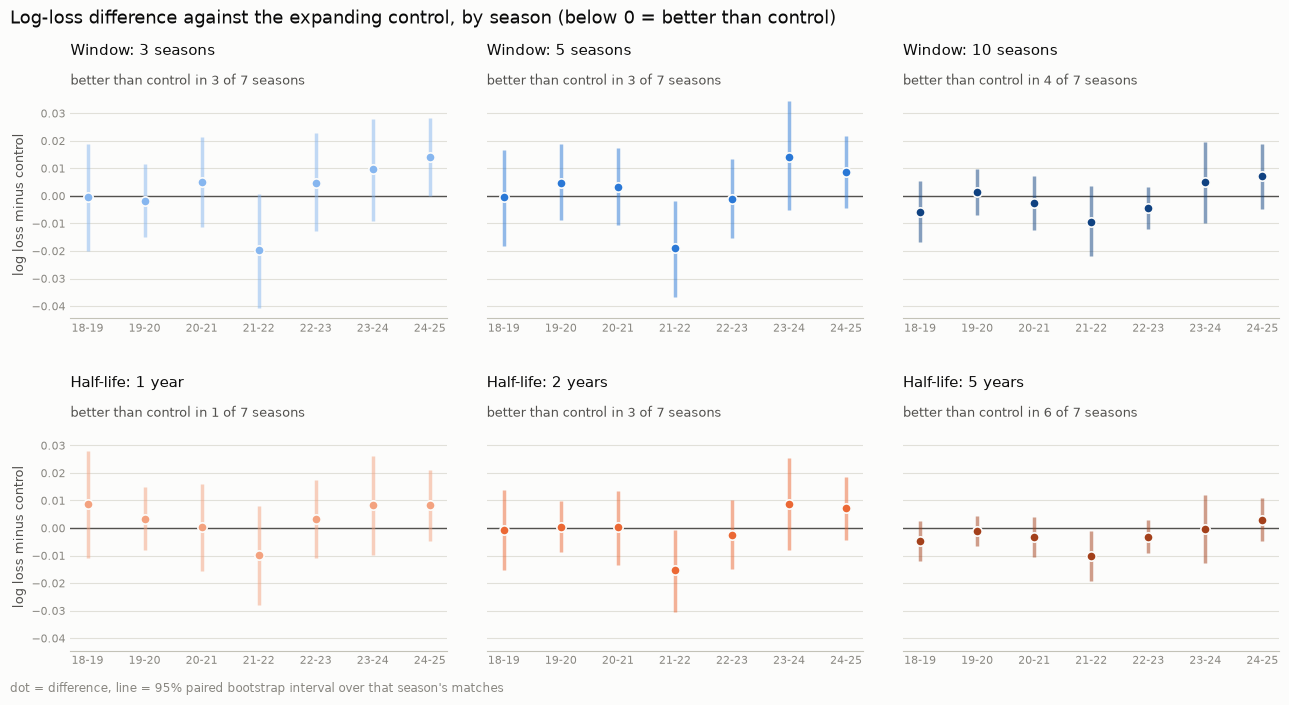

In [7]:
diffs = season_differences(predictions, metric="log_loss", forecasts=LABELS)
boot = seasonal_bootstrap(predictions, [(label, CONTROL.label) for label in OTHERS])

fig, axes = plt.subplots(2, 3, figsize=(13, 7), facecolor=SURFACE, sharey=True)
x = np.arange(len(BACKTEST_SEASONS))
for ax, label in zip(axes.ravel(), OTHERS):
    rows = boot[boot["a"] == label].set_index("season").loc[list(BACKTEST_SEASONS)]
    ax.axhline(0, color=INK_2, linewidth=1, zorder=1)
    ax.vlines(x, rows["ci_low"], rows["ci_high"], color=COLORS[label], linewidth=2.5, alpha=0.5, zorder=2)
    ax.scatter(x, rows["difference"], s=45, color=COLORS[label], edgecolors=SURFACE, linewidths=1.2, zorder=3)
    better = int((rows["difference"] < 0).sum())
    ax.set_xticks(x, [SEASON_LABELS[s][2:] for s in BACKTEST_SEASONS], fontsize=8, color=INK_2)
    style_axes(ax)
    set_title(ax, label, f"better than control in {better} of {len(x)} seasons", size=10.5)
for ax in axes[:, 0]:
    ax.set_ylabel("log loss minus control", fontsize=9, color=INK_2)
fig.suptitle("Log-loss difference against the expanding control, by season (below 0 = better than control)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.text(0.01, 0.005, "dot = difference, line = 95% paired bootstrap interval over that season's matches",
         fontsize=8.5, color=MUTED)
fig.tight_layout(h_pad=3, w_pad=2.5, rect=(0, 0.02, 1, 1))
save_figure(fig, "35_recency_by_season.png")
plt.show()

**Interpretation**

- **2021-22 stands out.** Every strategy beats the control there by 0.009–0.020 log loss. That
  season the control's tuning chose almost no regularisation (`C = 1.0`), while all recency
  strategies chose strong regularisation. Much of that season's gain may come from regularisation
  rather than from recency itself.
- **Short memories are unstable.**
  - The 3- and 5-season windows gain about 0.02 in 2021-22 but lose 0.009–0.014 in 2023-24 and
    2024-25.
  - The 1-year half-life is worse than the control in 6 of 7 seasons.
- **Half-life 5 years is the only strategy better than the control in 6 of 7 seasons.** Its
  seasonal gains are small (0.000–0.010), and it is worse in 2024-25 by 0.003.
- **Window 10 and half-life 2 are mixed:** better in 4 and 3 seasons respectively.
- **Within a single season, most intervals include zero.** One season of 380 matches cannot
  separate strategies that differ by a few thousandths.

## 4. Pooled performance over all seven seasons

In [8]:
pooled = pooled_metrics(predictions).loc[LABELS + [BOOKMAKER_LABEL, BASELINE]]
control_row = pooled.loc[CONTROL.label]
pooled_display = pooled[["matches"] + METRICS].copy()
for metric in ("log_loss", "brier"):
    pooled_display[f"{metric} vs control"] = pooled[metric] - control_row[metric]
pooled_display.style.format({"matches": "{:,}", "accuracy": "{:.2%}", "macro_f1": "{:.4f}", "log_loss": "{:.4f}",
                             "brier": "{:.4f}", "log_loss vs control": "{:+.4f}", "brier vs control": "{:+.4f}"})

,matches,accuracy,macro_f1,log_loss,brier,log_loss vs control,brier vs control
Expanding (control),"2,657",53.52%,0.4223,0.9834,0.5854,+0.0000,+0.0000
Window: 3 seasons,"2,657",53.11%,0.4181,0.9850,0.5861,+0.0016,+0.0007
Window: 5 seasons,"2,657",53.67%,0.4246,0.9848,0.5856,+0.0014,+0.0002
Window: 10 seasons,"2,657",53.71%,0.4113,0.9822,0.5839,-0.0012,-0.0015
Half-life: 1 year,"2,657",53.14%,0.4188,0.9867,0.5868,+0.0032,+0.0015
Half-life: 2 years,"2,657",53.26%,0.4166,0.9831,0.5845,-0.0003,-0.0009
Half-life: 5 years,"2,657",53.97%,0.4202,0.9807,0.5834,-0.0027,-0.0020
Bookmaker (Bet365),"2,657",54.42%,0.4147,0.9602,0.5698,-0.0232,-0.0155
Baseline,"2,657",41.25%,0.1947,1.0921,0.6621,+0.1086,+0.0767


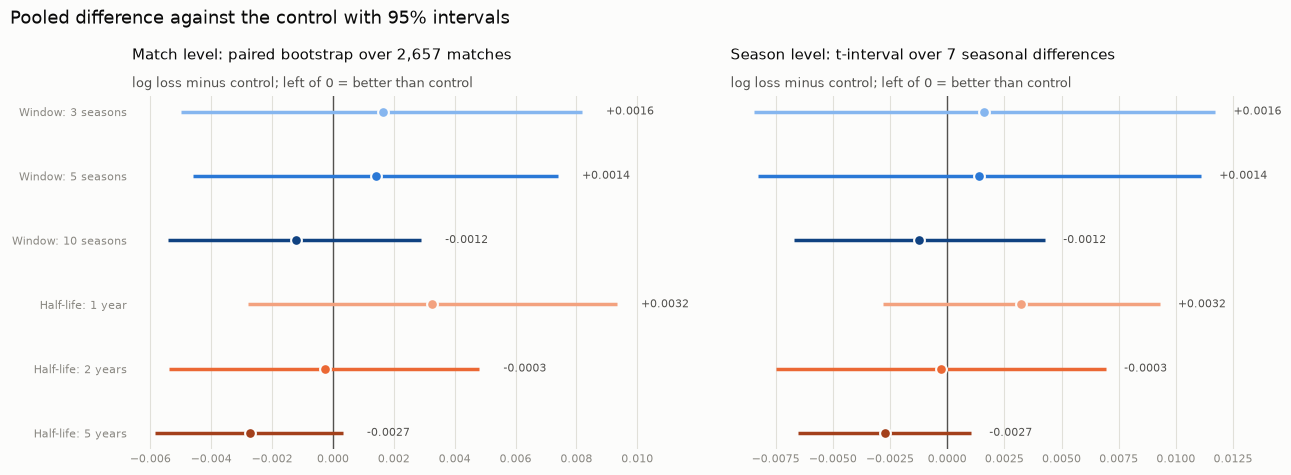

In [9]:
pairs = [(label, CONTROL.label) for label in OTHERS]
match_level = {m: pooled_bootstrap(predictions, pairs, metric=m).set_index("a") for m in ("log_loss", "brier")}
season_level = {m: season_level_summary(predictions, metric=m, forecasts=LABELS) for m in ("log_loss", "brier")}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), facecolor=SURFACE, sharey=True)
y = np.arange(len(OTHERS))[::-1]
for ax, (title, low, high, centre) in zip(axes, (
    ("Match level: paired bootstrap over 2,657 matches", "ci_low", "ci_high", "difference"),
    ("Season level: t-interval over 7 seasonal differences", "ci_low", "ci_high", "mean_difference"),
)):
    table = match_level["log_loss"] if centre == "difference" else season_level["log_loss"]
    ax.axvline(0, color=INK_2, linewidth=1, zorder=1)
    for yi, label in zip(y, OTHERS):
        r = table.loc[label]
        ax.hlines(yi, r[low], r[high], color=COLORS[label], linewidth=2.5, zorder=2)
        ax.scatter(r[centre], yi, s=60, color=COLORS[label], edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(r[high] + 0.0008, yi, f"{r[centre]:+.4f}", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, OTHERS, fontsize=9, color=INK_2)
    style_axes(ax, grid="x")
    ax.spines["bottom"].set_visible(False)
    set_title(ax, title, "log loss minus control; left of 0 = better than control", size=10.5)
fig.suptitle("Pooled difference against the control with 95% intervals", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=3)
save_figure(fig, "36_recency_pooled_intervals.png")
plt.show()

**Interpretation**

- **Pooled log loss differs from the control by at most 0.003 either way:**
  - best: half-life 5 years, 0.9807 against 0.9834 (−0.0027)
  - worst: half-life 1 year, 0.9867 (+0.0032)

  The gap to the bookmaker (0.9602) is about 0.023, roughly eight times the largest recency
  gain.
- **Match level:** every log-loss interval includes zero. For half-life 5 years it runs from
  −0.0058 to +0.0003, so the bootstrap puts it just short of a clear improvement.
- **The Brier score tells a similar story:**
  - Half-life 5 years: −0.0020, with a match-level interval from −0.0040 to −0.00001, technically
    excluding zero by a hair.
  - The season-level interval (−0.0040 to +0.00002) technically includes it.

  Either way the result sits right on the boundary, and it is the best of six strategies tested.
  With six comparisons, one of them landing on such a boundary is quite likely by chance alone.
- **Accuracy and macro F1** move by at most 0.5 points and about 0.011 respectively, in both
  directions, with no pattern.

## 5. Is any improvement consistent? Season-level sensitivity

Matches in the same season share conditions (teams, rules, the season's overall home advantage),
so the match-level bootstrap is optimistic about precision. Here each **season** counts as one
observation of "strategy minus control":

- **Seasons better / worse:** in how many of the seven seasons the strategy had the lower log loss.
- **Sign test:** the exact two-sided binomial p-value for that count. Even 7 out of 7 would only
  give p = 0.016, and 6 out of 7 gives p = 0.125.
- **t-interval:** the mean seasonal difference with a 95% t-interval (6 degrees of freedom).
- **Leave one season out:** the pooled difference recomputed seven times, each time without one
  season. If the range stays on one side of zero, no single season drives the result.

In [10]:
fmt = {"seasons": "{:.0f}", "mean_difference": "{:+.4f}", "sd": "{:.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}",
       "seasons_better": "{:.0f}", "seasons_worse": "{:.0f}", "sign_test_p": "{:.3f}", "pooled_difference": "{:+.4f}",
       "leave_one_out_min": "{:+.4f}", "leave_one_out_max": "{:+.4f}"}
display(season_level["log_loss"].style.format(fmt).set_caption("Log loss: strategy minus control, season level"))
season_level["brier"].style.format(fmt).set_caption("Brier score: strategy minus control, season level")

,seasons,mean_difference,sd,ci_low,ci_high,seasons_better,seasons_worse,sign_test_p,pooled_difference,leave_one_out_min,leave_one_out_max
Window: 3 seasons,7,+0.0016,0.0109,-0.0085,+0.0117,3,4,1.000,+0.0016,-0.0004,+0.0052
Window: 5 seasons,7,+0.0014,0.0105,-0.0083,+0.0111,3,4,1.000,+0.0014,-0.0007,+0.0048
Window: 10 seasons,7,-0.0012,0.0059,-0.0067,+0.0043,4,3,1.000,-0.0012,-0.0026,+0.0001
Half-life: 1 year,7,+0.0032,0.0065,-0.0028,+0.0093,1,6,0.125,+0.0032,+0.0023,+0.0054
Half-life: 2 years,7,-0.0003,0.0078,-0.0075,+0.0069,3,4,1.000,-0.0003,-0.0017,+0.0022
Half-life: 5 years,7,-0.0027,0.0041,-0.0065,+0.0010,6,1,0.125,-0.0027,-0.0037,-0.0015


,seasons,mean_difference,sd,ci_low,ci_high,seasons_better,seasons_worse,sign_test_p,pooled_difference,leave_one_out_min,leave_one_out_max
Window: 3 seasons,7,+0.0007,0.0063,-0.0052,+0.0066,2,5,0.453,+0.0007,-0.0003,+0.0028
Window: 5 seasons,7,+0.0002,0.0059,-0.0053,+0.0057,3,4,1.000,+0.0002,-0.0010,+0.0021
Window: 10 seasons,7,-0.0015,0.0035,-0.0047,+0.0018,4,3,1.000,-0.0015,-0.0022,-0.0006
Half-life: 1 year,7,+0.0015,0.0039,-0.0021,+0.0051,2,5,0.453,+0.0015,+0.0007,+0.0027
Half-life: 2 years,7,-0.0009,0.0046,-0.0051,+0.0033,4,3,1.000,-0.0009,-0.0018,+0.0005
Half-life: 5 years,7,-0.0020,0.0022,-0.0040,+0.0000,6,1,0.125,-0.0020,-0.0025,-0.0014


In [11]:
others = {}
for metric in ("accuracy", "macro_f1"):
    s = season_level_summary(predictions, metric=metric, forecasts=LABELS)
    others[metric] = s[["pooled_difference", "seasons_better", "seasons_worse"]]
pd.concat(others, axis=1).style.format("{:+.4f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "pooled_difference"]]).format(
    "{:.0f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["seasons_better", "seasons_worse"]]]).set_caption(
    "Accuracy and macro F1: strategy minus control (higher is better)")

**Interpretation**

- **Half-life 5 years is the most consistent:**
  - better than the control in 6 of 7 seasons on log loss and on Brier score;
  - every leave-one-season-out pooled difference stays negative (−0.0037 to −0.0015 log loss),
    so no single season produces the result.
- **But the evidence is weak in absolute terms:**
  - the sign test gives p = 0.125 (6 of 7 is the best possible outcome short of 7 of 7);
  - the season-level t-interval for log loss (−0.0065 to +0.0010) includes zero;
  - the average gain, 0.003 log loss, is about 0.3% of the control's score.
- **Window 10 seasons** is slightly better on average, but only in 4 of 7 seasons. Its
  leave-one-out range touches zero.
- **Windows 3 and 5 and half-life 1 year are not improvements.** Pooled they are worse, and their
  seasonal results swing widely (windows 3 and 5 have the largest standard deviations).

## Recommendation

**Keep the expanding, equally weighted training history as the default.** None of the six recency
strategies improves on it by more than the uncertainty in seven seasons of results.

What the evidence does support:
- **Do not shorten the memory.** Rolling windows of 3–5 seasons and a 1-year half-life throw away
  or down-weight too much data. They are no better on average and are less stable from season to
  season.
- **Mild down-weighting is a reasonable candidate, not a proven improvement.**
  - A 5-year half-life was slightly better in 6 of 7 seasons, with a pooled gain of about 0.003
    log loss.
  - The gain is small, its intervals reach zero at both the match and the season level, and it was
    the best of six strategies tried.
  - It should be confirmed on seasons that were not used here before being adopted. For example,
    compare it with the control on 2026-27 once the season is complete, as a single pre-specified
    check.
- **Recency is not where the remaining gap is.** The best strategy closes about a tenth of the
  0.023 log-loss gap to the bookmaker. As in commits 7–10, better information (new features) is
  more promising than re-weighting the same history.

## Limitations

- Logistic Regression only; tree models might respond differently to weighting.
- Seven evaluation seasons, and the inner tuning uses a single validation season.
- The weights affect the model fit, not the imputer or scaler.
- Part of the 2021-22 gain looks like a regularisation effect rather than a recency effect.

## Next steps

- **Commit 12:** final documentation and presentation. The recency framework (`src/recency.py`)
  can be reused for tree models or new features later.